In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:", round(
        torch.cuda.get_device_properties(0).total_memory / (1024**3), 2
    ), "GB")
else:
    print("GPU not available. Running on CPU.")

Selected Device: cpu
GPU not available. Running on CPU.


In [3]:
class InferenceModel(nn.Module):
    def __init__(self):
        super(InferenceModel, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(1024, 2048),
            nn.ReLU(),
            nn.Linear(2048, 1024),
            nn.ReLU(),
            nn.Linear(1024, 10)
        )

    def forward(self, x):
        return self.network(x)


model = InferenceModel().to(device)
model.eval()

print("Inference model created successfully!")

Inference model created successfully!


In [4]:
batch_sizes = [32, 64, 128, 256, 512]

input_features = 1024

print("Batch Sizes:", batch_sizes)
print("Input Features:", input_features)

Batch Sizes: [32, 64, 128, 256, 512]
Input Features: 1024


In [5]:
results = []

def synchronize():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


for batch_size in batch_sizes:

    # Generate CPU input data
    input_data = torch.randn(batch_size, input_features)

    # Measure H2D transfer
    synchronize()
    start = time.perf_counter()

    gpu_input = input_data.to(device)

    synchronize()
    h2d_time = time.perf_counter() - start

    # Measure GPU inference
    synchronize()
    start = time.perf_counter()

    with torch.no_grad():
        output = model(gpu_input)

    synchronize()
    inference_time = time.perf_counter() - start

    # Measure D2H transfer
    synchronize()
    start = time.perf_counter()

    cpu_output = output.cpu()

    synchronize()
    d2h_time = time.perf_counter() - start

    # Calculate total execution time
    total_time = h2d_time + inference_time + d2h_time

    # Calculate traffic in MB
    h2d_traffic = input_data.numel() * input_data.element_size() / (1024**2)
    d2h_traffic = output.numel() * output.element_size() / (1024**2)

    # Calculate throughput
    throughput = batch_size / total_time

    results.append({
        "Batch Size": batch_size,
        "H2D Time (ms)": h2d_time * 1000,
        "Inference Time (ms)": inference_time * 1000,
        "D2H Time (ms)": d2h_time * 1000,
        "Total Time (ms)": total_time * 1000,
        "H2D Traffic (MB)": h2d_traffic,
        "D2H Traffic (MB)": d2h_traffic,
        "Throughput (samples/sec)": throughput
    })

print("Inference execution completed!")

Inference execution completed!


In [6]:
df = pd.DataFrame(results)

print("GPU INFERENCE PERFORMANCE RESULTS")
display(df.round(3))

GPU INFERENCE PERFORMANCE RESULTS


,Batch Size,H2D Time (ms),Inference Time (ms),D2H Time (ms),Total Time (ms),H2D Traffic (MB),D2H Traffic (MB),Throughput (samples/sec)
0,32,0.029,42.229,0.021,42.279,0.125,0.001,756.877
1,64,0.007,17.130,0.019,17.156,0.250,0.002,3730.555
2,128,0.008,19.571,0.009,19.588,0.500,0.005,6534.714
3,256,0.011,36.149,0.009,36.169,1.000,0.010,7077.968
4,512,0.019,65.307,0.011,65.337,2.000,0.020,7836.322


In [7]:
for result in results:

    times = {
        "H2D Transfer": result["H2D Time (ms)"],
        "GPU Inference": result["Inference Time (ms)"],
        "D2H Transfer": result["D2H Time (ms)"]
    }

    bottleneck = max(times, key=times.get)

    print("\nBatch Size:", result["Batch Size"])
    print("Bottleneck:", bottleneck)
    print("Maximum Time:", round(times[bottleneck], 3), "ms")


Batch Size: 32
Bottleneck: GPU Inference
Maximum Time: 42.229 ms

Batch Size: 64
Bottleneck: GPU Inference
Maximum Time: 17.13 ms

Batch Size: 128
Bottleneck: GPU Inference
Maximum Time: 19.571 ms

Batch Size: 256
Bottleneck: GPU Inference
Maximum Time: 36.149 ms

Batch Size: 512
Bottleneck: GPU Inference
Maximum Time: 65.307 ms


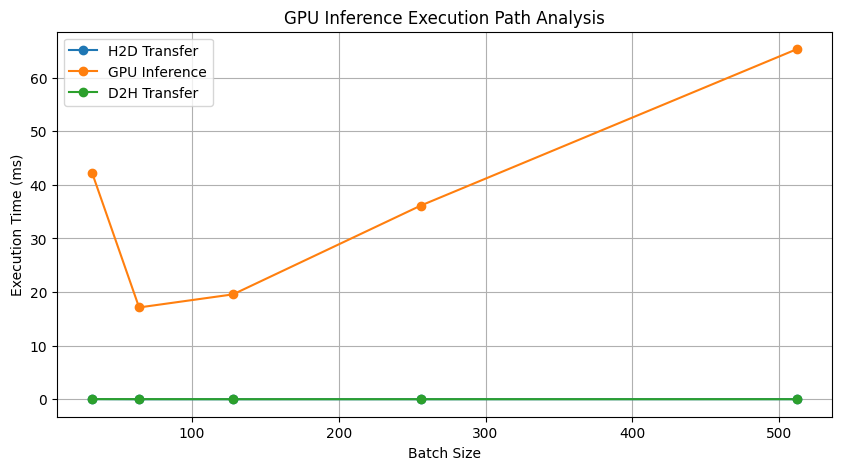

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(df["Batch Size"], df["H2D Time (ms)"],
         marker='o', label="H2D Transfer")

plt.plot(df["Batch Size"], df["Inference Time (ms)"],
         marker='o', label="GPU Inference")

plt.plot(df["Batch Size"], df["D2H Time (ms)"],
         marker='o', label="D2H Transfer")

plt.xlabel("Batch Size")
plt.ylabel("Execution Time (ms)")
plt.title("GPU Inference Execution Path Analysis")

plt.legend()
plt.grid(True)
plt.show()

In [9]:
df["Total Traffic (MB)"] = (
    df["H2D Traffic (MB)"] + df["D2H Traffic (MB)"]
)

print("DATA TRANSFER TRAFFIC ANALYSIS")

display(df[[
    "Batch Size",
    "H2D Traffic (MB)",
    "D2H Traffic (MB)",
    "Total Traffic (MB)"
]].round(3))

DATA TRANSFER TRAFFIC ANALYSIS


,Batch Size,H2D Traffic (MB),D2H Traffic (MB),Total Traffic (MB)
0,32,0.125,0.001,0.126
1,64,0.250,0.002,0.252
2,128,0.500,0.005,0.505
3,256,1.000,0.010,1.010
4,512,2.000,0.020,2.020


In [10]:
df["H2D Bandwidth (MB/s)"] = (
    df["H2D Traffic (MB)"] /
    (df["H2D Time (ms)"] / 1000)
)

df["D2H Bandwidth (MB/s)"] = (
    df["D2H Traffic (MB)"] /
    (df["D2H Time (ms)"] / 1000)
)

display(df[[
    "Batch Size",
    "H2D Bandwidth (MB/s)",
    "D2H Bandwidth (MB/s)"
]].round(2))

,Batch Size,H2D Bandwidth (MB/s),D2H Bandwidth (MB/s)
0,32,4330.65,58.59
1,64,35816.62,129.64
2,128,62774.64,560.73
3,256,92592.59,1075.98
4,512,102960.10,1843.79


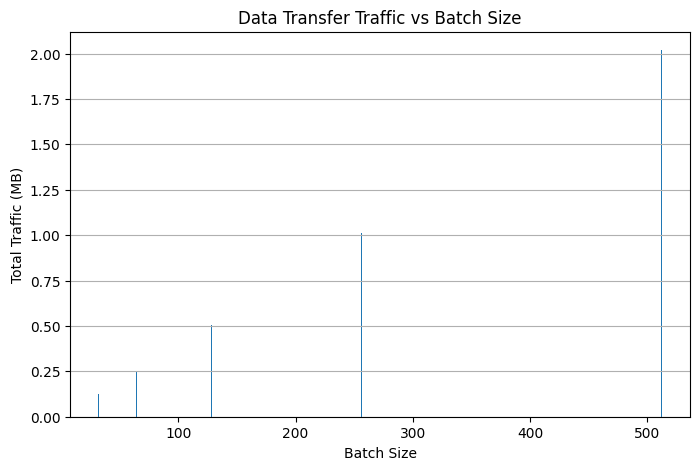

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(df["Batch Size"], df["Total Traffic (MB)"])

plt.xlabel("Batch Size")
plt.ylabel("Total Traffic (MB)")
plt.title("Data Transfer Traffic vs Batch Size")

plt.grid(axis="y")
plt.show()

In [12]:
print("FINAL SYSTEM-LEVEL BOTTLENECK ANALYSIS")

for _, row in df.iterrows():

    total = row["Total Time (ms)"]

    h2d_percent = row["H2D Time (ms)"] / total * 100
    inference_percent = row["Inference Time (ms)"] / total * 100
    d2h_percent = row["D2H Time (ms)"] / total * 100

    print("\nBatch Size:", int(row["Batch Size"]))

    print("H2D Overhead:", round(h2d_percent, 2), "%")
    print("GPU Computation:", round(inference_percent, 2), "%")
    print("D2H Overhead:", round(d2h_percent, 2), "%")

    bottleneck = max(
        h2d_percent,
        inference_percent,
        d2h_percent
    )

    if bottleneck == h2d_percent:
        print("Identified Bottleneck: CPU to GPU Transfer")
    elif bottleneck == inference_percent:
        print("Identified Bottleneck: GPU Computation")
    else:
        print("Identified Bottleneck: GPU to CPU Transfer")

FINAL SYSTEM-LEVEL BOTTLENECK ANALYSIS

Batch Size: 32
H2D Overhead: 0.07 %
GPU Computation: 99.88 %
D2H Overhead: 0.05 %
Identified Bottleneck: GPU Computation

Batch Size: 64
H2D Overhead: 0.04 %
GPU Computation: 99.85 %
D2H Overhead: 0.11 %
Identified Bottleneck: GPU Computation

Batch Size: 128
H2D Overhead: 0.04 %
GPU Computation: 99.91 %
D2H Overhead: 0.04 %
Identified Bottleneck: GPU Computation

Batch Size: 256
H2D Overhead: 0.03 %
GPU Computation: 99.95 %
D2H Overhead: 0.03 %
Identified Bottleneck: GPU Computation

Batch Size: 512
H2D Overhead: 0.03 %
GPU Computation: 99.95 %
D2H Overhead: 0.02 %
Identified Bottleneck: GPU Computation


In [13]:
print("========== EXPERIMENT SUMMARY ==========")

print("Device Used:", device)

print("Number of Batch Sizes Tested:", len(batch_sizes))

print("Average Inference Time:",
      round(df["Inference Time (ms)"].mean(), 3), "ms")

print("Average Total Execution Time:",
      round(df["Total Time (ms)"].mean(), 3), "ms")

print("Maximum Throughput:",
      round(df["Throughput (samples/sec)"].max(), 2),
      "samples/sec")

print("Maximum Data Traffic:",
      round(df["Total Traffic (MB)"].max(), 3), "MB")

========== EXPERIMENT SUMMARY ==========
Device Used: cpu
Number of Batch Sizes Tested: 5
Average Inference Time: 36.077 ms
Average Total Execution Time: 36.106 ms
Maximum Throughput: 7836.32 samples/sec
Maximum Data Traffic: 2.02 MB
